<a href="https://colab.research.google.com/github/alyairawan02/publicdiscussion_analysis/blob/main/PAKAI_AUGMENTASI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_excel('hasil_labeling_baru.xlsx')


In [ ]:
import random

# Fungsi augmentasi sederhana
def augment_text(text):
    if isinstance(text, str):
        words = text.split()
        if len(words) > 1:
            random.shuffle(words)
        return ' '.join(words)
    return text

In [ ]:
# Data awal
df = pd.read_excel('hasil_labeling_baru.xlsx')

# Hitung jumlah data tiap label
pos_data = df[df['sent_label'].str.upper() == 'POSITIVE']
neg_data = df[df['sent_label'].str.upper() == 'NEGATIVE']

# Target jumlah data per kelas
target = 1500

# Augmentasi POSITIVE
if len(pos_data) < target:
    n_aug_pos = target - len(pos_data)
    aug_pos = pos_data.sample(n=n_aug_pos, replace=True, random_state=42).copy()
    aug_pos['cleaning'] = aug_pos['cleaning'].apply(augment_text)
    aug_pos['sent_label'] = 'POSITIVE'
else:
    aug_pos = pd.DataFrame(columns=df.columns)  # Kosongkan kalau tidak perlu augmentasi

# Augmentasi NEGATIVE
if len(neg_data) < target:
    n_aug_neg = target - len(neg_data)
    aug_neg = neg_data.sample(n=n_aug_neg, replace=True, random_state=42).copy()
    aug_neg['cleaning'] = aug_neg['cleaning'].apply(augment_text)
    aug_neg['sent_label'] = 'NEGATIVE'
else:
    aug_neg = pd.DataFrame(columns=df.columns)  # Kosongkan kalau tidak perlu augmentasi

# Gabungkan semua data
df_final = pd.concat([df, aug_pos, aug_neg], ignore_index=True)

# Cek hasil distribusi
print(df_final['sent_label'].value_counts())
print(f"\n✅ Augmentasi lengkap berhasil. Jumlah data akhir: {len(df_final)}")

sent_label
NEGATIVE    1500
POSITIVE    1500
NEUTRAL     1052
Name: count, dtype: int64

✅ Augmentasi lengkap berhasil. Jumlah data akhir: 4052


In [ ]:
print(df_final['sent_label'].value_counts())

sent_label
NEGATIVE    1500
POSITIVE    1500
NEUTRAL     1052
Name: count, dtype: int64


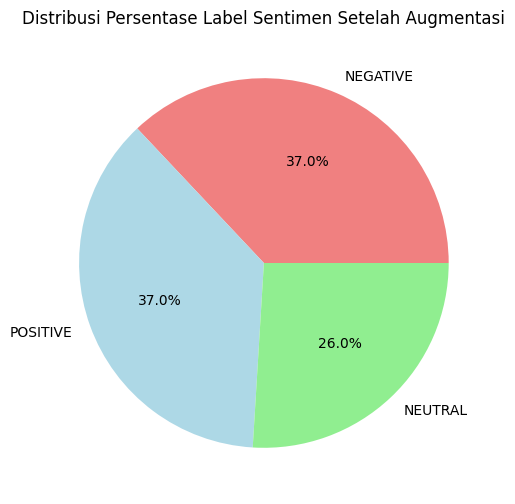

In [ ]:
import matplotlib.pyplot as plt

# Hitung jumlah label
label_counts = df_final['sent_label'].value_counts()
label_percent = (label_counts / label_counts.sum()) * 100

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(label_percent, labels=label_percent.index, autopct='%1.1f%%', colors=['lightcoral', 'lightblue', 'lightgreen'])
plt.title('Distribusi Persentase Label Sentimen Setelah Augmentasi')
plt.show()

In [ ]:
print(df_final['sent_label'].unique())


['NEGATIVE' 'POSITIVE' 'NEUTRAL']


In [ ]:
df_final.columns

Index(['created_at', 'full_text', 'cleaning', 'case_folding', 'tokenize',
       'stemming_data', 'sent_label', 'sent_score'],
      dtype='object')

In [ ]:
!pip install transformers torch

  Using cached nvidia_cudnn_cu12-9.1.0.70-py3-none-manylinux2014_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cusolver_cu12-11.6.1.9-py3-none-manylinux2014_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cusparse_cu12-12.3.1.170-py3-none-manylinux2014_x86_64.whl.metadata (1.6 kB)
Using cached nvidia_cudnn_cu12-9.1.0.70-py3-none-manylinux2014_x86_64.whl (664.8 MB)
Using cached nvidia_cusolver_cu12-11.6.1.9-py3-none-manylinux2014_x86_64.whl (127.9 MB)
Using cached nvidia_cusparse_cu12-12.3.1.170-py3-none-manylinux2014_x86_64.whl (207.5 MB)
  Attempting uninstall: nvidia-cusparse-cu12
    Found existing installation: nvidia-cusparse-cu12 12.5.1.3
    Uninstalling nvidia-cusparse-cu12-12.5.1.3:
      Successfully uninstalled nvidia-cusparse-cu12-12.5.1.3
  Attempting uninstall: nvidia-cudnn-cu12
    Found existing installation: nvidia-cudnn-cu12 9.3.0.75
    Uninstalling nvidia-cudnn-cu12-9.3.0.75:
      Successfully uninstalled nvidia-cudnn-cu12-9.3.0.75
  Attempting uninstall: n

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# Encode label (pastikan kolom label bernama 'sent_label')
label_encoder = LabelEncoder()
df_final['encoded_label'] = label_encoder.fit_transform(df_final['sent_label'])

In [ ]:
# Membersihkan kolom 'cleaning' dari NaN atau baris kosong
df_final = df_final[df_final['stemming_data'].notna()]
df_final = df_final[df_final['stemming_data'].str.strip() != '']
df_final.loc[:, 'stemming_data'] = df_final['stemming_data'].astype(str)
df_final = df_final.reset_index(drop=True)

In [ ]:
df_final['stemming_data'] = df_final['stemming_data'].fillna('').astype(str)

In [ ]:
#tokenizing

# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(df_final['stemming_data'])

sequences = tokenizer.texts_to_sequences(df_final['stemming_data'])

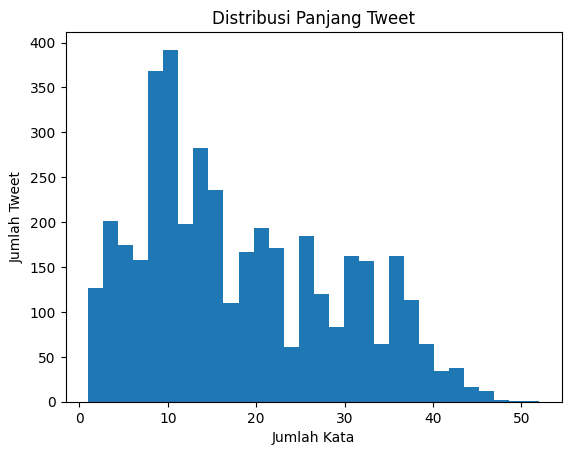

In [ ]:
import matplotlib.pyplot as plt

# Hitung panjang setiap tweet
tweet_lengths = [len(tweet.split()) for tweet in df_final['stemming_data']]

# Visualisasikan distribusinya
plt.hist(tweet_lengths, bins=30)
plt.title('Distribusi Panjang Tweet')
plt.xlabel('Jumlah Kata')
plt.ylabel('Jumlah Tweet')
plt.show()

In [ ]:
# Padding
max_len = 50  #  distribusi panjang teks
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encoding untuk label
onehot_labels = to_categorical(df_final['encoded_label'], num_classes=3)

# 0 → [1. 0. 0.]
# 1 → [0. 1. 0.]
# 2 → [0. 0. 1.]

In [ ]:
df.head(5)

,created_at,full_text,cleaning,case_folding,tokenize,stemming_data,sent_label,sent_score
0,Fri Dec 27 22:21:19 +0000 2024,@opposite6892 Orang gila 300 T ruginya,Orang gila T ruginya,orang gila t ruginya,"['orang', 'gila', 't', 'ruginya']",orang gila t rugi,NEGATIVE,0.999949
1,Fri Dec 27 22:14:23 +0000 2024,@zakariamlk nanti juga kalau mau minjem lagi p...,nanti juga kalau mau minjem lagi paling diunb...,nanti juga kalau mau minjem lagi paling diunb...,"['nanti', 'juga', 'kalau', 'mau', 'minjem', 'l...",nanti juga kalau mau minjem lagi paling diunbl...,NEGATIVE,0.700405
2,Fri Dec 27 17:49:09 +0000 2024,@nonerahm @ruangtaktik @bliblidotcom nahini le...,nahini lebih manuk akal,nahini lebih manuk akal,"['nahini', 'lebih', 'manuk', 'akal']",nahini lebih manuk akal,POSITIVE,0.854760
3,Fri Dec 27 15:21:39 +0000 2024,Warga x yang ga napak tanah bingung lihat ini....,Warga x yang ga napak tanah bingung lihat ini ...,warga x yang ga napak tanah bingung lihat ini ...,"['warga', 'x', 'yang', 'ga', 'napak', 'tanah',...",warga x yang ga napak tanah bingung lihat ini ...,NEGATIVE,0.999818
4,Fri Dec 27 15:04:34 +0000 2024,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,"['hidup', 'lagi', 'capek', 'capeknya', 'jaket'...",hidup lagi capek capek jaket vintage ku colong...,NEGATIVE,0.999881


In [ ]:
#split data (test set & training set)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, onehot_labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
#visualisasi split data
print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (3241, 50)
Shape X_test: (811, 50)
Shape y_train: (3241, 3)
Shape y_test: (811, 3)


In [ ]:
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 3241
Jumlah data testing: 811


In [ ]:
import numpy as np
import pandas as pd

# Mengembalikan dari one-hot ke angka kelas
train_labels = np.argmax(y_train, axis=1)
test_labels = np.argmax(y_test, axis=1)

label_map = {0: 'NEGATIVE', 1: 'NEUTRAL', 2: 'POSITIVE'}

train_labels_named = pd.Series(train_labels).map(label_map)
test_labels_named = pd.Series(test_labels).map(label_map)

print("Distribusi sentimen (train):")
print(train_labels_named.value_counts())

print("\nDistribusi sentimen (test):")
print(test_labels_named.value_counts())

Distribusi sentimen (train):
POSITIVE    1219
NEGATIVE    1210
NEUTRAL      812
Name: count, dtype: int64

Distribusi sentimen (test):
NEGATIVE    290
POSITIVE    281
NEUTRAL     240
Name: count, dtype: int64


In [ ]:
#SMOTE

from imblearn.over_sampling import SMOTE
from tensorflow.keras.utils import to_categorical
import numpy as np

# 1. Ubah label dari one-hot ke label integer
y_train_labels = np.argmax(y_train, axis=1)

# 2. Terapkan SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled_labels = smote.fit_resample(X_train, y_train_labels)

# 3. Mengembalikan hasil SMOTE ke one-hot encoding
y_train_resampled = to_categorical(y_train_resampled_labels, num_classes=3)

# 4. Cek hasil
print("Shape X_train_resampled:", X_train_resampled.shape)
print("Shape y_train_resampled:", y_train_resampled.shape)

Shape X_train_resampled: (3657, 50)
Shape y_train_resampled: (3657, 3)


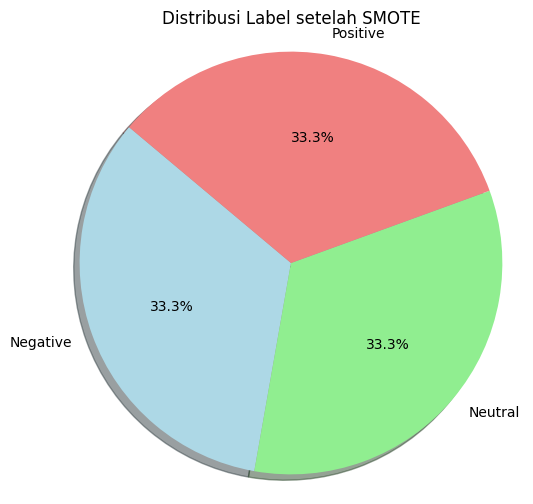

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil label hasil SMOTE (dari one-hot ke label)
resampled_labels = np.argmax(y_train_resampled, axis=1)

# Hitung jumlah per label
unique, counts = np.unique(resampled_labels, return_counts=True)
label_names = ['Negative', 'Neutral', 'Positive']
colors = ['lightblue', 'lightgreen', 'lightcoral']

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=label_names, autopct='%1.1f%%', colors=colors, startangle=140, shadow=True)
plt.title('Distribusi Label setelah SMOTE')
plt.axis('equal')
plt.show()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 42s 360ms/step - accuracy: 0.3520 - loss: 1.6486 - val_accuracy: 0.4316 - val_loss: 1.4912 - learning_rate: 1.0000e-04
Epoch 2/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 19s 324ms/step - accuracy: 0.3930 - loss: 1.5367 - val_accuracy: 0.4562 - val_loss: 1.4758 - learning_rate: 1.0000e-04
Epoch 3/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 20s 325ms/step - accuracy: 0.4335 - loss: 1.4649 - val_accuracy: 0.5327 - val_loss: 1.4555 - learning_rate: 1.0000e-04
Epoch 4/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 31s 542ms/step - accuracy: 0.4778 - loss: 1.3871 - val_accuracy: 0.6375 - val_loss: 1.4253 - learning_rate: 1.0000e-04
Epoch 5/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 28s 319ms/step - accuracy: 0.5526 - loss: 1.2924 - val_accuracy: 0.6535 - val_loss: 1.3849 - learning_rate: 1.0000e-04
Epoch 6/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 22s 344ms/step - accuracy: 0.5924 - loss: 1.2249 - val_accuracy: 0.7053 - val_loss: 1.3272 - learning_rate: 1.0000e-04
Epoch 7/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 18s 307ms/step - acc

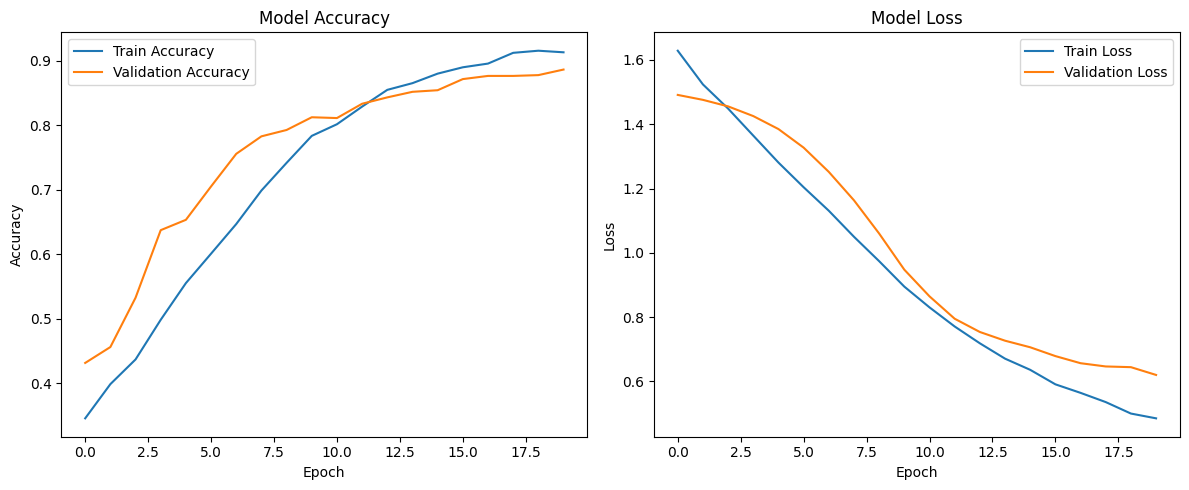

In [ ]:
#LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import regularizers
from tensorflow.keras.layers import SpatialDropout1D

# Arsitektur model
model = Sequential()
model.add(Embedding(input_dim=10000, output_dim=128, input_length=200)) #embedding layer
model.add(SpatialDropout1D(0.2))

# Bidirectional LSTM
model.add(Bidirectional(LSTM(64, return_sequences=True, dropout=0.3, recurrent_dropout=0.2)))
model.add(Bidirectional(LSTM(32, return_sequences=False, dropout=0.3, recurrent_dropout=0.2)))
model.add(BatchNormalization())

# Dense layer
model.add(Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.01)))
model.add(Dropout(0.4))

# Output layer
model.add(Dense(3, activation='softmax'))  # 3 kelas: negatif, netral, positif

# Compile
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

# Train model
history = model.fit(
    X_train_resampled, y_train_resampled,
    epochs=20,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[early_stop, reduce_lr]
)

# Visualisasi hasil
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#data testing

# Evaluasi ke data test
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.6201
Test Accuracy: 0.8866


26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 139ms/step
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90       290
     Neutral       0.89      0.82      0.85       240
    Positive       0.86      0.94      0.90       281

    accuracy                           0.89       811
   macro avg       0.89      0.88      0.88       811
weighted avg       0.89      0.89      0.89       811



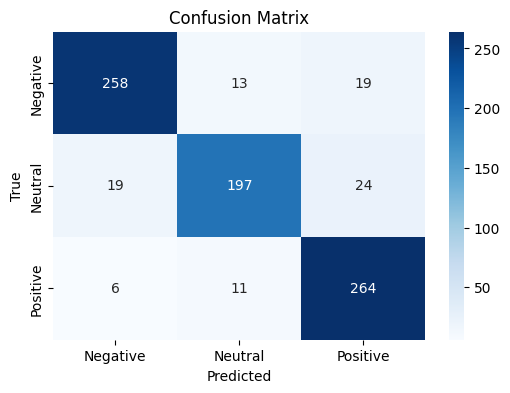

In [ ]:
#confusion matrix
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Prediksi label
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Klasifikasi
print(classification_report(y_true, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

# Confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()